# Task 5: Account Security Monitoring (Anomaly Detection)

**เป้าหมาย:** ระบุบัญชีที่มีพฤติกรรมผิดปกติ (`task5` = 1) จากข้อมูลพฤติกรรม 4 ช่วงเวลาติดต่อกัน (ฟีเจอร์ลงท้าย `_1` ถึง `_4`)

**Metric:** F3 ของคลาส anomaly (ให้น้ำหนัก recall มากกว่า precision 9 เท่า) ดังนั้นการพลาด anomaly จริงมีต้นทุนสูงกว่าการตั้งธงเกิน

**ลักษณะของโจทย์:** มีเพียง `test.csv` ไม่มีข้อมูล train และไม่มี label จึงเป็น unsupervised anomaly detection โดยสมบูรณ์ ทุกขั้นตอนในโน้ตบุ๊กนี้ไม่ใช้ label ใด ๆ

**แนวคิดหลัก:** จากการสำรวจข้อมูลพบว่า anomaly ไม่ได้กระจายแบบสุ่ม แต่เป็น "กลุ่มย่อย" ที่แยกตัวออกจากประชากรปกติอย่างชัดเจนบนฟีเจอร์ไม่กี่ตัว
ฟีเจอร์ของบัญชีปกติแทบเป็นอิสระต่อกัน กลุ่มผิดปกติจึงปรากฏเป็นก้อนที่มีช่องว่าง (gap) คั่นจากการกระจายปกติใน histogram
เราจึงตั้งเกณฑ์ของแต่ละกลุ่มไว้ภายในช่องว่างนั้น แทนการใช้ Isolation Forest หรือ autoencoder ที่ให้คะแนนรวมแบบหยาบ

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, gaussian_kde
import warnings
warnings.filterwarnings('ignore')

DATA = Path(os.environ.get('CPE342_DATA', '../data'))
OUT = Path('output'); OUT.mkdir(exist_ok=True)
te = pd.read_csv(DATA / '05_anomaly_detection' / 'test.csv')
print('test shape:', te.shape)

test shape: (25889, 123)


## 1. ฟีเจอร์สรุปต่อแถว

ฟีเจอร์ทั้งหมดในส่วนนี้คำนวณจากข้อมูลในแถวเดียวกันเท่านั้น (row-wise)
- `m(b, ps)`: ค่าเฉลี่ยของฟีเจอร์ `b` ในช่วงเวลา `ps` ใช้ลดสัญญาณรบกวนรายช่วง
- `dl`: ระยะทางของตำแหน่งล็อกอินในช่วงที่ 4 เทียบกับค่าเฉลี่ยของช่วง 1 ถึง 3 (หน่วยองศา lat/lon) ใช้จับการย้ายตำแหน่งแบบกะทันหัน

In [2]:
def m(b, ps):
    return te[[f'{b}_{i}' for i in ps]].mean(axis=1)

lat = te[[f'login_lat_{i}' for i in range(1, 5)]].values
lon = te[[f'login_lon_{i}' for i in range(1, 5)]].values
dl = np.sqrt((lat[:, 3] - np.nanmean(lat[:, :3], 1))**2 + (lon[:, 3] - np.nanmean(lon[:, :3], 1))**2)

S = pd.DataFrame({
    'location shift (dl)': np.nan_to_num(dl),
    'location_changes_4': te.location_changes_4,
    'skill_trajectory_4': te.skill_trajectory_4,
    'ip_hash_entropy (mean p1-3)': m('ip_hash_entropy', [1, 2, 3]),
    'login_time_variance (mean p1-3)': m('login_time_variance', [1, 2, 3]),
    'behavior_stability': te.behavior_stability,
    'activity_level (mean p1-3)': m('activity_level', [1, 2, 3]),
    'communication_frequency (mean p1-3)': m('communication_frequency', [1, 2, 3]),
})
S.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
location shift (dl),25889.0,1.914,9.977,0.000,0.359,0.638,0.953,122.509
location_changes_4,24645.0,1.696,1.752,0.000,0.760,1.499,2.246,19.911
skill_trajectory_4,24581.0,1.188,12.450,-20.131,-3.325,0.037,3.491,149.946
ip_hash_entropy (mean p1-3),25888.0,0.547,0.096,0.008,0.487,0.550,0.611,0.799
login_time_variance (mean p1-3),25885.0,4.960,1.839,0.123,3.428,4.931,6.440,9.865
behavior_stability,24632.0,0.819,0.089,0.201,0.761,0.822,0.886,0.950
activity_level (mean p1-3),25888.0,0.992,0.310,0.115,0.737,0.987,1.236,1.866
communication_frequency (mean p1-3),25884.0,0.743,0.277,0.007,0.514,0.743,0.965,1.452


## 2. หลักฐานจาก histogram: กลุ่มผิดปกติแยกตัวด้วยช่องว่าง

กราฟด้านล่างแสดง histogram (แกน y แบบ log เพื่อให้เห็นกลุ่มเล็ก) ของฟีเจอร์ที่ใช้นิยามแต่ละกลุ่ม เส้นประสีแดงคือเกณฑ์ที่เลือก
จะเห็นว่าเกณฑ์อยู่ในบริเวณที่จำนวนแถวลดลงจนเกือบเป็นศูนย์ระหว่างก้อนหลัก (บัญชีปกติ) กับก้อนเล็ก (กลุ่มผิดปกติ) จึงไม่ไวต่อการเลื่อนเกณฑ์เล็กน้อย
ข้อยกเว้นคือ `location_changes_4` ซึ่งช่องว่างอยู่ราว 3.7 ถึง 5 แต่เกณฑ์ตั้งไว้ที่ 8 อย่างไรก็ตามแถวในช่วง 5 ถึง 8 เกือบทั้งหมด (76 จาก 80 แถว) ถูกจับด้วยกฎ `dl > 5` ของกลุ่มเดียวกันอยู่แล้ว

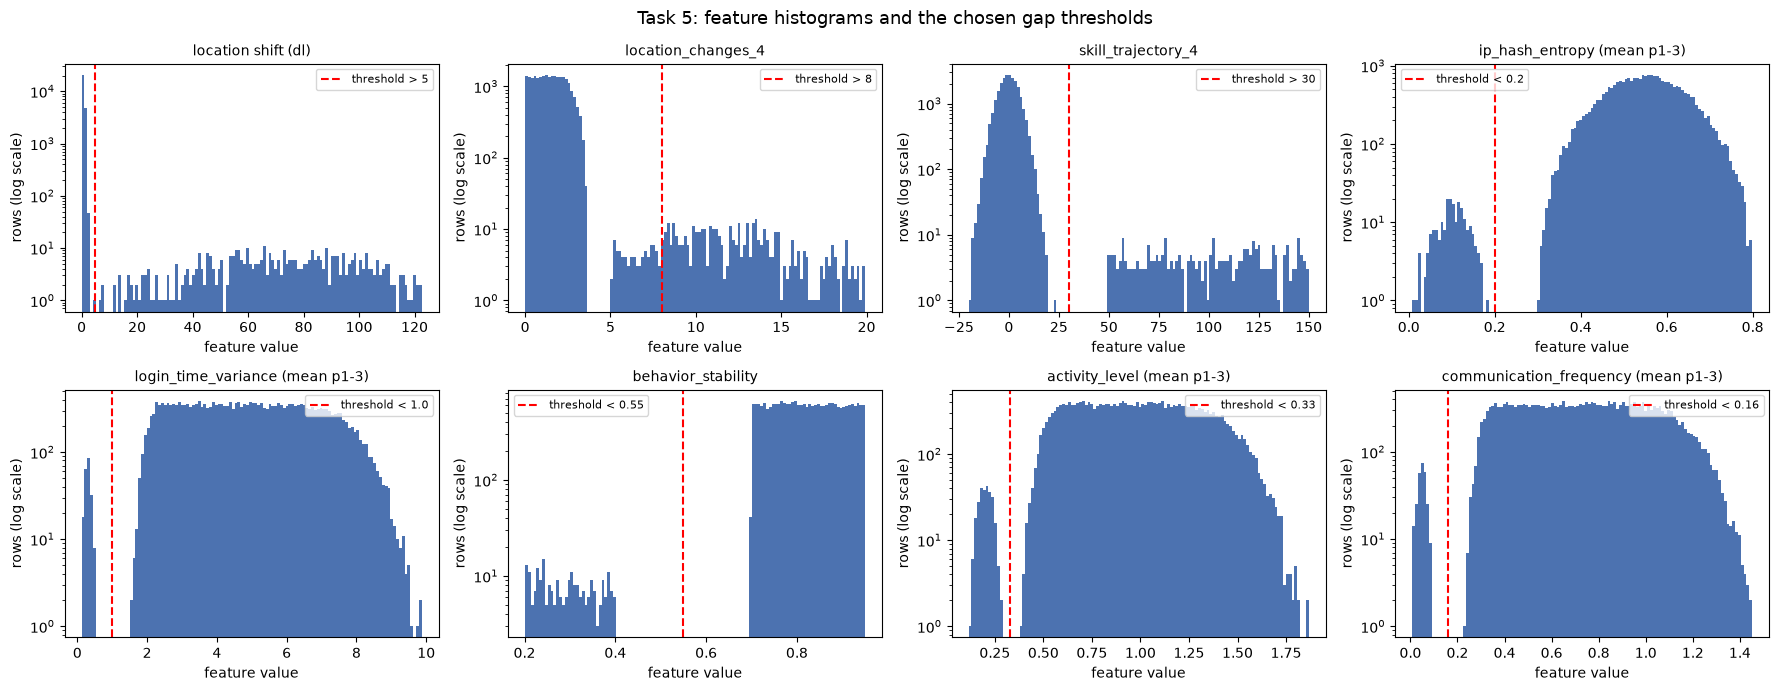

In [3]:
TH = {
    'location shift (dl)': ('>', 5),
    'location_changes_4': ('>', 8),
    'skill_trajectory_4': ('>', 30),
    'ip_hash_entropy (mean p1-3)': ('<', 0.2),
    'login_time_variance (mean p1-3)': ('<', 1.0),
    'behavior_stability': ('<', 0.55),
    'activity_level (mean p1-3)': ('<', 0.33),
    'communication_frequency (mean p1-3)': ('<', 0.16),
}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (c, (op, t)) in zip(axes.ravel(), TH.items()):
    v = S[c].dropna()
    ax.hist(v, bins=120, color='#4C72B0')
    ax.axvline(t, color='red', ls='--', label=f'threshold {op} {t}')
    ax.set_yscale('log'); ax.set_title(c, fontsize=10)
    ax.set_xlabel('feature value'); ax.set_ylabel('rows (log scale)'); ax.legend(fontsize=8)
fig.suptitle('Task 5: feature histograms and the chosen gap thresholds', fontsize=13)
plt.tight_layout(); plt.show()

## 3. กลุ่มผิดปกติ 6 กลุ่มที่นิยามด้วยกฎ

| กลุ่ม | ความหมาย | กฎ |
|---|---|---|
| `loc` | ตำแหน่ง/การย้ายที่ในช่วงที่ 4 เปลี่ยนแบบกระโดด | `dl > 5` หรือ `location_changes_4 > 8` |
| `skill` | ฝีมือพุ่งขึ้นผิดปกติในช่วงที่ 4 (เช่น ซื้อบัญชีหรือให้คนอื่นเล่นแทน) | `skill_trajectory_4 > 30` |
| `bot` | IP แทบไม่เปลี่ยนหรือเวลาล็อกอินสม่ำเสมอเกินมนุษย์ | mean `ip_hash_entropy` < 0.2 หรือ mean `login_time_variance` < 1.0 |
| `B` | ความเสถียรของพฤติกรรมต่ำผิดปกติ | `behavior_stability < 0.55` |
| `act` | ระดับกิจกรรมต่ำผิดปกติ | mean `activity_level` < 0.33 |
| `comm` | การสื่อสารต่ำผิดปกติ | mean `communication_frequency` < 0.16 |

การใช้ค่าเฉลี่ยของช่วง 1 ถึง 3 สำหรับ `act` และ `comm` สำคัญมาก เพราะค่ารายช่วงมีสัญญาณรบกวนสูง ในการทดลองช่วงแรกที่ใช้ drift score รวม เราจับกลุ่ม `act` ได้เพียง 71 จาก 265 แถว และ `comm` ได้ 115 จาก 263 แถว

In [4]:
G = pd.DataFrame({
    'loc': (np.nan_to_num(dl) > 5) | (te.location_changes_4.fillna(0) > 8),
    'skill': te.skill_trajectory_4.fillna(0) > 30,
    'bot': (m('ip_hash_entropy', [1, 2, 3]) < 0.2) | (m('login_time_variance', [1, 2, 3]) < 1.0),
    'B': te.behavior_stability < 0.55,
    'act': m('activity_level', [1, 2, 3]) < 0.33,
    'comm': m('communication_frequency', [1, 2, 3]) < 0.16,
})
summary = pd.DataFrame({'rows flagged': G.sum(), 'share of test (%)': (100 * G.mean()).round(2)})
print('rows in 2 or more groups:', int((G.sum(axis=1) >= 2).sum()))
summary

rows in 2 or more groups: 0


,rows flagged,share of test (%)
loc,510,1.97
skill,299,1.15
bot,207,0.80
B,246,0.95
act,265,1.02
comm,263,1.02


## 4. Spike ในช่วงที่ 4 (z-score เทียบกับพฤติกรรมเดิมของแถวนั้น)

นอกจาก 6 กลุ่มหลัก ยังมีแถวที่ฟีเจอร์ในช่วงที่ 4 กระโดดออกจากค่าเฉลี่ยของช่วง 1 ถึง 3 หลายตัวพร้อมกัน
สำหรับแต่ละฟีเจอร์ฐาน (27 ตัว) เราคำนวณ z-score ของ `x_4 - mean(x_1..x_3)` โดย
1. ประมาณความแปรปรวนภายในบุคคลจาก residual ของช่วง 1 ถึง 3 (แต่ละช่วงเทียบกับค่าเฉลี่ยของอีกสองช่วง) ใช้ MAD เพื่อให้ทนต่อ outlier
2. ให้ scale ขึ้นกับระดับของฟีเจอร์ โดยแบ่ง 20 ช่วงตาม quantile ของค่าเฉลี่ย แล้ว interpolate ระหว่างช่วง
3. ประมาณ scale จากแถวที่ยังไม่ถูกจัดเป็นกลุ่มผิดปกติชัดเจน (`known`) เพื่อไม่ให้กลุ่มผิดปกติทำให้ scale กว้างเกินจริง

แถวที่มีฟีเจอร์อย่างน้อย 2 ตัวที่ |z| > 5 จะถูกตั้งธงเพิ่ม (ตัดฟีเจอร์นับจำนวนที่เป็นจำนวนเต็มเล็ก ๆ ออก เพราะ z-score ของค่าไม่ต่อเนื่องไม่น่าเชื่อถือ)

In [5]:
base = ['login_count', 'location_changes', 'device_count', 'ip_hash_entropy', 'login_time_variance',
        'session_duration_mean', 'session_duration_std', 'play_pattern_consistency', 'activity_level',
        'skill_rating', 'skill_trajectory', 'kda_mean', 'kda_std', 'accuracy_mean', 'accuracy_std',
        'reaction_time_mean', 'reaction_time_std', 'performance_stability', 'purchase_frequency',
        'purchase_amount_mean', 'purchase_amount_std', 'refund_count', 'currency_transfers',
        'friend_adds', 'friend_removes', 'communication_frequency', 'guild_changes']

# rows that are clearly anomalous already (used only to keep them out of the scale estimate)
known = ((np.nan_to_num(dl) > 5) | (te.location_changes_4.fillna(0) > 8) | (te.skill_trajectory_4.fillna(0) > 30)
         | (te.ip_hash_entropy_1.fillna(1) < 0.2) | (te.behavior_stability < 0.5)).values

def mad(x):
    x = x[~np.isnan(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))

Zs = {}
for b in base:
    Mx = te[[f'{b}_{i}' for i in range(1, 5)]].values
    mu = np.nanmean(Mx[:, :3], axis=1)
    R = np.stack([Mx[:, t] - np.nanmean(np.delete(Mx[:, :3], t, axis=1), axis=1) for t in range(3)], 1)
    qs = np.nanquantile(mu[~known], np.linspace(0, 1, 21)); qs[0] = -np.inf; qs[-1] = np.inf
    bi = np.clip(np.searchsorted(qs, mu, side='right') - 1, 0, 19)
    sig = np.array([mad(R[(bi == k) & ~known].ravel()) / np.sqrt(1.5) for k in range(20)])
    cen = np.array([np.nanmedian(mu[(bi == k) & ~known]) for k in range(20)])
    s_row = np.interp(mu, cen, sig)
    Zs[b] = (Mx[:, 3] - mu) / (s_row * np.sqrt(4 / 3) + 1e-12)
Z = pd.DataFrame(Zs).drop(columns=['device_count', 'refund_count', 'guild_changes', 'friend_removes'])

n_big = (Z.abs() > 5).sum(axis=1)
extra = (n_big >= 2).values
in_groups = G.any(axis=1).values
print('rows with >= 2 period-4 spikes:', int(extra.sum()), '| not already in the 6 groups:', int((extra & ~in_groups).sum()))

rows with >= 2 period-4 spikes: 806 | not already in the 6 groups: 17


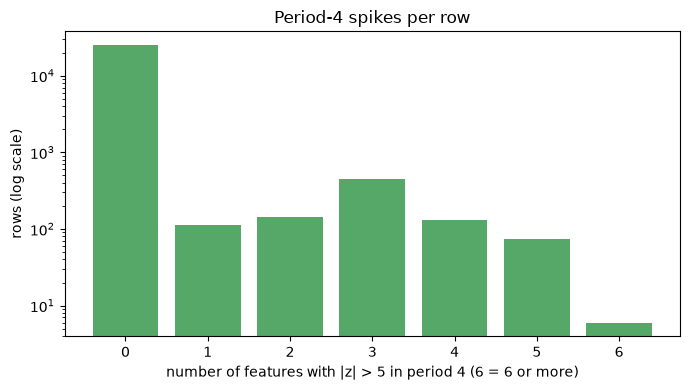

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
vc = n_big.clip(upper=6).value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color='#55A868')
ax.set_yscale('log'); ax.set_xlabel('number of features with |z| > 5 in period 4 (6 = 6 or more)')
ax.set_ylabel('rows (log scale)'); ax.set_title('Period-4 spikes per row')
plt.tight_layout(); plt.show()

## 5. กลุ่มที่ 7: กลุ่มความแปรปรวนสูงที่ซ่อนอยู่

หลังจากตั้งธง 6 กลุ่มแรก เรายังคาดว่ามี anomaly หลงเหลืออยู่ราว 200 ถึง 300 แถว จึงสแกน "มุม" ของทุกคู่ฟีเจอร์ในแถวที่ยังไม่ถูกตั้งธง
เนื่องจากฟีเจอร์ของบัญชีปกติแทบเป็นอิสระต่อกัน ความหนาแน่นในมุมใดมุมหนึ่งจึงควรเท่ากับผลคูณของ marginal
มุมที่มีจำนวนแถวเกินกว่าที่คาดอย่างมีนัยสำคัญบ่งชี้กลุ่มซ่อน ผลการสแกนพบกลุ่มที่มีค่าเฉลี่ย 4 ช่วงของ `kda_std` (ราว 0.86), `accuracy_std` (ราว 10.4) และ `performance_stability` (ราว 0.90) สูงพร้อมกัน

กลุ่มนี้ซ้อนทับกับประชากรปกติบางส่วน จึงไม่ใช้เกณฑ์แข็ง แต่คำนวณ posterior ของการเป็นสมาชิกกลุ่ม
- ความหนาแน่นของกลุ่ม: Gaussian 3 มิติ ประมาณจากแกนกลางของกลุ่ม (ขยาย sd 1.3 เท่าเพื่อชดเชยการตัดขอบกล่อง)
- ความหนาแน่นพื้นหลัง: ผลคูณของ KDE รายฟีเจอร์ของแถวที่ยังไม่ถูกตั้งธง (ใช้สมมติฐานความเป็นอิสระ)
- prior 0.009 (ราว 230 แถวจาก 25,889)

In [7]:
fl6 = in_groups | extra
un = ~fl6

def L(b, ps=(1, 2, 3, 4)):
    return te[[f'{b}_{i}' for i in ps]].mean(axis=1)

D = pd.DataFrame({'ks': L('kda_std'), 'as': L('accuracy_std'), 'ps': L('performance_stability')})
ok = D.notna().all(axis=1).values
U = D[un & ok]
bk = {c: gaussian_kde(U[c].values, bw_method=0.05) for c in D}
core = U.ks.between(0.8, 0.95) & U['as'].between(9.5, 11.2) & U.ps.between(0.87, 0.93)
g = U[core]
mu = g.mean().values
sd = np.sqrt(np.diag(np.cov(g.values.T))) * 1.3
cov = np.diag(sd**2)
print('core rows:', len(g), '| group mean:', mu.round(3), '| sd:', sd.round(3))

X = D[ok].values
pg = multivariate_normal(mu, cov).pdf(X)
pb = np.prod([bk[c](D.loc[ok, c].values) for c in D], axis=0)
prior = 0.009
post = np.zeros(len(D))
post[ok] = prior * pg / (prior * pg + (1 - prior) * pb)
print('expected group size (sum of posterior over unflagged rows):', round(post[un].sum()))

core rows: 189 | group mean: [ 0.861 10.389  0.899] | sd: [0.043 0.537 0.019]


expected group size (sum of posterior over unflagged rows): 231


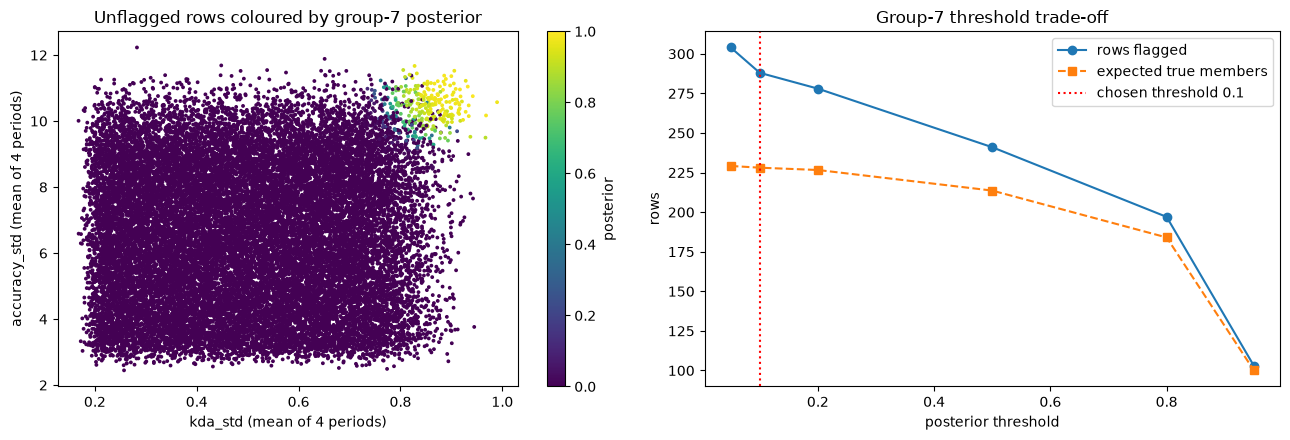

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sc = axes[0].scatter(U.ks, U['as'], c=post[un & ok], s=3, cmap='viridis', vmin=0, vmax=1)
axes[0].set_xlabel('kda_std (mean of 4 periods)'); axes[0].set_ylabel('accuracy_std (mean of 4 periods)')
axes[0].set_title('Unflagged rows coloured by group-7 posterior'); fig.colorbar(sc, ax=axes[0], label='posterior')
ts = [0.05, 0.1, 0.2, 0.5, 0.8, 0.95]
nf = [int(((post > t) & un).sum()) for t in ts]
etp = [post[(post > t) & un].sum() for t in ts]
axes[1].plot(ts, nf, 'o-', label='rows flagged')
axes[1].plot(ts, etp, 's--', label='expected true members')
axes[1].axvline(0.1, color='red', ls=':', label='chosen threshold 0.1')
axes[1].set_xlabel('posterior threshold'); axes[1].set_ylabel('rows'); axes[1].set_title('Group-7 threshold trade-off')
axes[1].legend(); plt.tight_layout(); plt.show()

**การเลือกเกณฑ์ posterior > 0.1:** สำหรับ F-beta การตั้งธงแถวหนึ่งเพิ่มคะแนนเมื่อความน่าจะเป็นที่แถวนั้นเป็น anomaly สูงกว่าประมาณ F/(1+β²)
เมื่อ β = 3 และ F อยู่ราว 0.99 ค่านี้ประมาณ 0.1 แถวที่ posterior ต่ำกว่านี้จึงไม่คุ้มที่จะตั้งธง ส่วนแถวที่สูงกว่าคุ้มแม้จะมี false positive บ้าง

## 6. รวมผลและสร้างไฟล์คำตอบ

In [9]:
g7 = (post > 0.1) & un
flag = fl6 | g7
parts = pd.Series({**G.sum().to_dict(),
                   'period-4 spikes (new rows)': int((extra & ~in_groups).sum()),
                   'group 7 (new rows)': int(g7.sum()),
                   'total flagged': int(flag.sum())})
print(parts.to_string())
print(f'flag rate: {flag.mean():.4f}')

pred = pd.DataFrame({'id': [f'ANS{i + 1:05d}' for i in range(len(te))], 'task5': flag.astype(int)})
pred.to_csv(OUT / 'task5_pred.csv', index=False)
pred.task5.value_counts()

loc                            510
skill                          299
bot                            207
B                              246
act                            265
comm                           263
period-4 spikes (new rows)      17
group 7 (new rows)             288
total flagged                 2095
flag rate: 0.0809


task5
0    23794
1     2095
Name: count, dtype: int64

## 7. สรุป

- Task 5 ไม่มีข้อมูล train และ label จึงแก้ด้วยการค้นหากลุ่มย่อยที่ผิดปกติโดยตรง แทนการใช้คะแนน anomaly แบบรวม
- พบกลุ่มผิดปกติ 7 กลุ่มที่แยกจากกัน (ตำแหน่ง, ฝีมือพุ่ง, bot, ความเสถียรต่ำ, กิจกรรมต่ำ, การสื่อสารต่ำ และกลุ่มความแปรปรวนสูง) รวมกับ spike หลายฟีเจอร์ในช่วงที่ 4 ตั้งธงทั้งหมด 2,095 แถว (8.1%)
- เกณฑ์เกือบทุกตัวอยู่ในช่องว่างของ histogram จึงทนต่อการเลื่อนเกณฑ์ และสอดคล้องกับ metric F3 ที่ให้ความสำคัญกับ recall
- จากคะแนนบน public leaderboard ที่เปลี่ยนเฉพาะ Task 5 ระหว่าง submission ต่าง ๆ ประเมินได้ว่า F3 ของ Task 5 อยู่ราว 0.995 การสแกนเพิ่มเติมไม่พบกลุ่มที่ 8 (ค่า z สูงสุด 3.8 ซึ่งอยู่ในระดับสัญญาณรบกวน)